In [82]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

In [83]:
gss <- read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss |> glimpse()

Rows: 75,699
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”


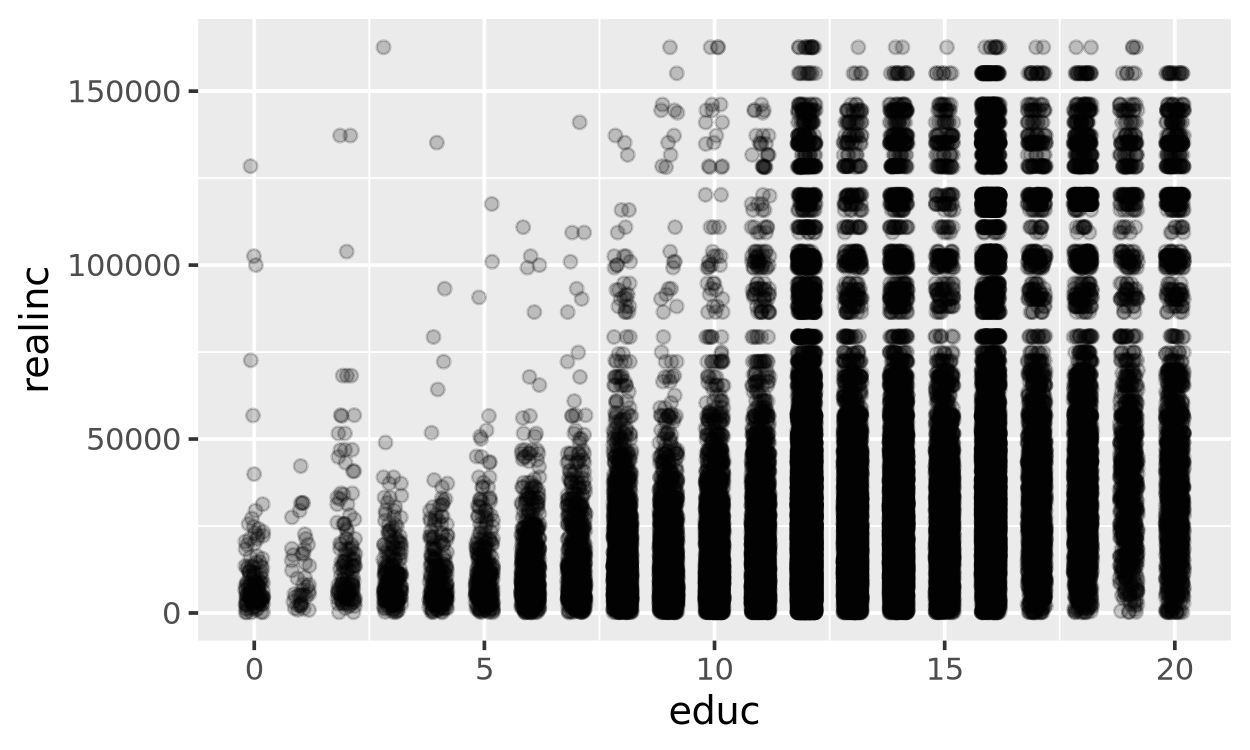

In [84]:
ggplot(gss, aes(x = educ, y = realinc)) +
    geom_point(alpha = 0.2, position = position_jitter(width = 0.2, height=0.2))

In [85]:
set.seed(512)

n_params <- 100

param_grid <- tibble(
    intercept = runif(n_params, -20000, 30000),
    slope     = runif(n_params, 0, 6000)
)

param_grid

    intercept   slope    
1     -733.3641 4021.0628
2   -13306.6671 5588.2671
3     2837.9626 2807.8803
4    26621.7060 3163.2785
5    12187.4454 5875.6614
6   -10131.8255 2670.7435
7    28687.8354  902.2154
8    21455.6851 3770.9850
9   -14078.0412  229.5765
10    5276.5044 3887.3530
11    6649.0867 3166.4580
12   16171.5429  212.4009
13   -4865.2151 2293.1949
14   22172.9691 1573.9211
15   -3866.4979 3638.2874
16   -4709.6373 3057.6540
17  -13468.5074 3567.0946
18    -266.0556 2035.7652
19   24653.7437 1046.3262
20   19001.7292 1639.1139
21   17124.6085 5725.2086
22  -12278.2692  244.7311
23  -13500.8252 3258.6560
24   22476.4134  877.8395
25   24529.0307 3616.2928
26    3024.7155  489.5461
27    4360.2746 4016.9712
28    1165.2134 3044.2047
29    8513.2611 5694.5823
30   -6504.7318 1597.0328
⋮   ⋮           ⋮        
71   25972.576  1592.0101
72   18362.846  3079.2808
73  -19013.714  5722.5225
74   17320.429  1255.6994
75    2756.882   263.3754
76  -16006.807  3269.2628
77  -17269.4

In [86]:
educ_means <- gss |>
    filter(!is.na(educ)) |>
    group_by(educ) |>
    summarise(mean_realinc = mean(realinc, na.rm = TRUE))

educ_means

   educ mean_realinc
1   0   11642.46    
2   1   12030.38    
3   2   18330.32    
4   3   11435.07    
5   4   11648.34    
6   5   12475.96    
7   6   13052.99    
8   7   14831.50    
9   8   16368.22    
10  9   16591.07    
11 10   19086.99    
12 11   21033.08    
13 12   27420.73    
14 13   28963.78    
15 14   33150.92    
16 15   33850.90    
17 16   47273.18    
18 17   45686.97    
19 18   53723.48    
20 19   57324.80    
21 20   60106.37    

In [87]:
calc_rmse <- function(intercept, slope, data) {
    preds <- intercept + slope * data$educ
    sqrt(mean((data$mean_realinc - preds)^2, na.rm = TRUE))
}

param_grid <- param_grid |>
    rowwise() |>
    mutate(rmse = calc_rmse(intercept, slope, educ_means)) |>
    ungroup()

param_grid

    intercept   slope     rmse     
1     -733.3641 4021.0628 16970.529
2   -13306.6671 5588.2671 25417.195
3     2837.9626 2807.8803  7804.095
4    26621.7060 3163.2785 32232.623
5    12187.4454 5875.6614 49054.415
6   -10131.8255 2670.7435 12246.447
7    28687.8354  902.2154 15613.967
8    21455.6851 3770.9850 33796.615
9   -14078.0412  229.5765 41490.048
10    5276.5044 3887.3530 20300.413
11    6649.0867 3166.4580 13726.547
12   16171.5429  212.4009 17283.449
13   -4865.2151 2293.1949 10968.841
14   22172.9691 1573.9211 13732.246
15   -3866.4979 3638.2874 11105.213
16   -4709.6373 3057.6540  7433.285
17  -13468.5074 3567.0946 10436.934
18    -266.0556 2035.7652  9684.161
19   24653.7437 1046.3262 13385.083
20   19001.7292 1639.1139 11648.245
21   17124.6085 5725.2086 51799.026
22  -12278.2692  244.7311 39643.436
23  -13500.8252 3258.6560 11244.615
24   22476.4134  877.8395 12222.236
25   24529.0307 3616.2928 35053.549
26    3024.7155  489.5461 23311.023
27    4360.2746 4016.9712 20

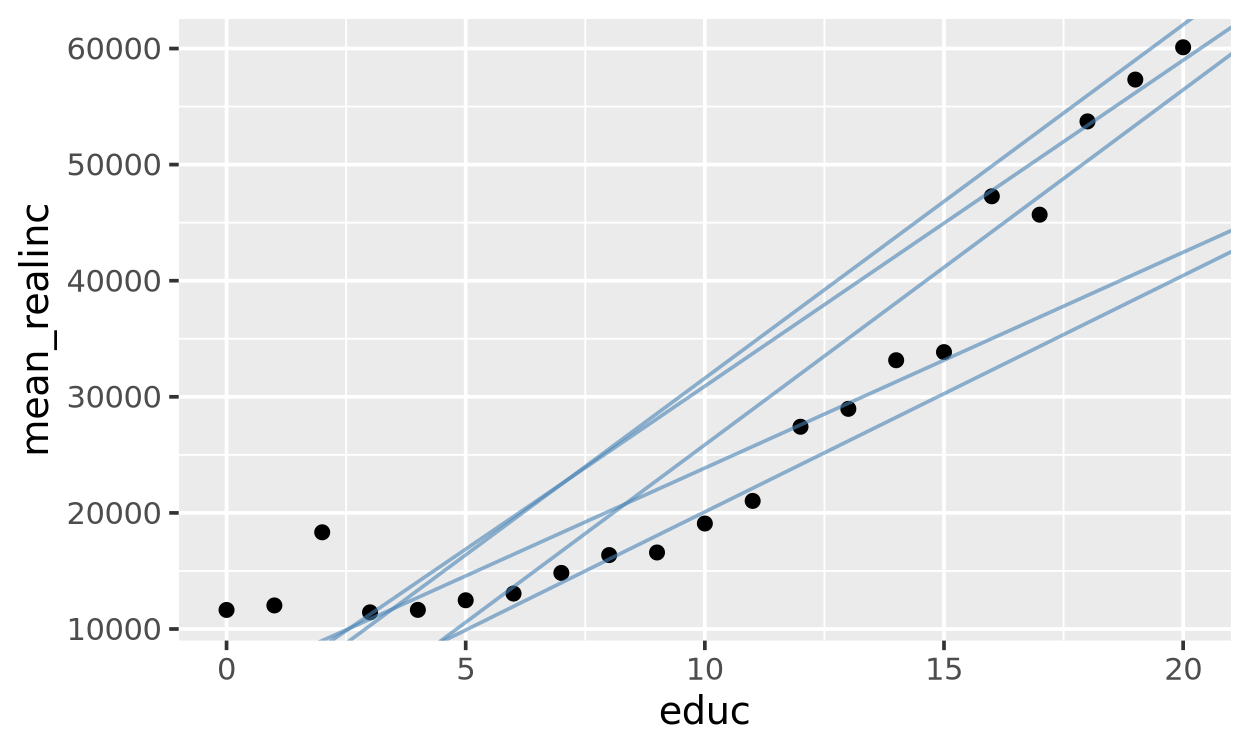

In [88]:
best_models <- param_grid |>
    slice_min(rmse, n = 5)

ggplot(educ_means, aes(x = educ, y = mean_realinc)) +
    geom_point() +
    geom_abline(
        data = best_models,
        aes(intercept = intercept, slope = slope),
        color = 'steelblue', alpha = 0.6
    )

In [89]:
calc_rmse(intercept = 0, slope = 3000, data = educ_means)

[1] 7803.716

# A tibble: 21 × 2
    educ mean_realinc
   <int>        <dbl>
 1     0       11642.
 2     1       12030.
 3     2       18330.
 4     3       11435.
 5     4       11648.
 6     5       12476.
 7     6       13053.
 8     7       14832.
 9     8       16368.
10     9       16591.
# ℹ 11 more rows
# ℹ Use `print(n = ...)` to see more rows


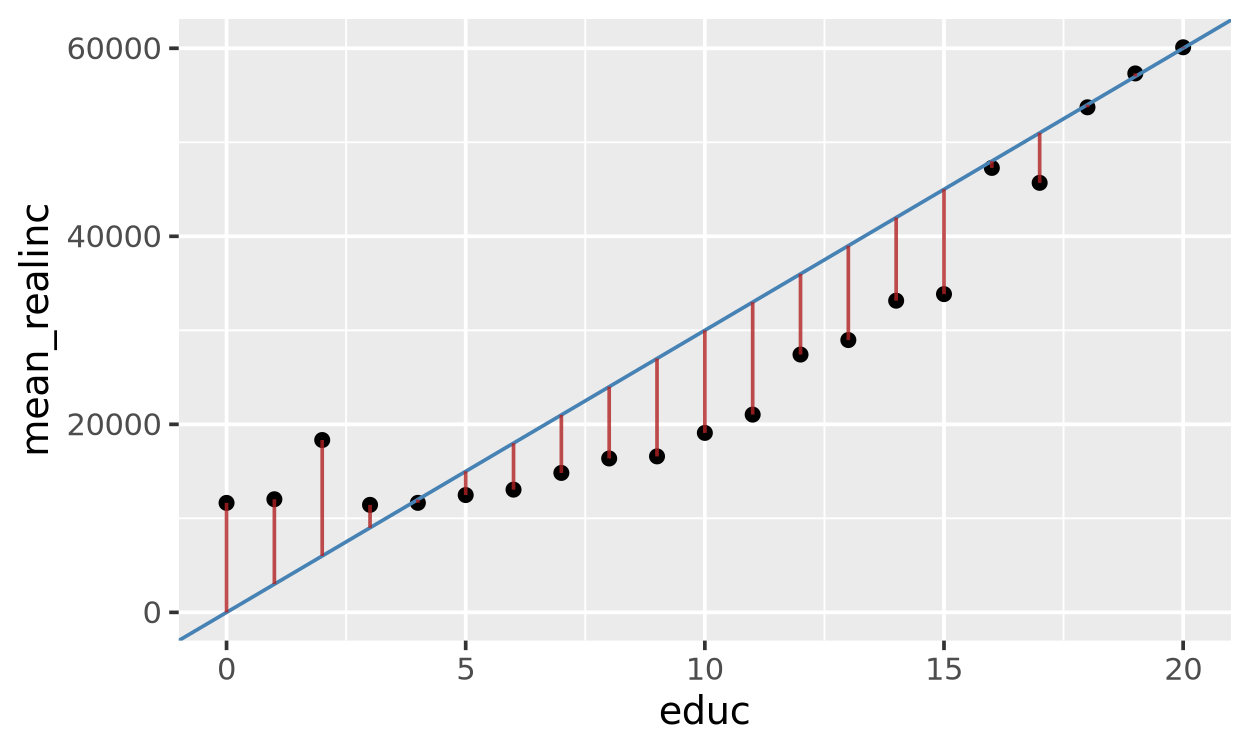

In [90]:
print(educ_means)

educ_means |>
    mutate(fitted = 0 + 3000 * educ) |>
    ggplot(aes(x = educ, y = mean_realinc)) +
    geom_point() +
    geom_abline(intercept = 0, slope = 3000, color = 'steelblue') +
    geom_segment(
        aes(xend = educ, yend = fitted),
        color = 'firebrick', alpha = 0.8
    )

Steps for creating a model:

1. Pick the model form:

$$y_i = \beta_0 + \beta_1 x_i + \varepsilon_i$$

where $y_i$ is `realinc`, $x_i$ is `educ`, $\beta_0$ is the intercept, $\beta_1$ is the slope, and $\varepsilon_i$ is the error.

2. Design a way to evaluate different model parameters.
3. Optimize our parameter values.